In [1]:
## what should this code do? ##

#1 Generate 1 infinite phase screen
#2 Make phase structure function
   #2.1 randomly choose 10,000 pairs of points in the screen
        # (statistically speaking, this is the lowest number where we can normally quote 2 sig fig for error quantity)
   #2.2 measure phase difference (absolute value) between those two points
   #2.3 measure distance between those two points
   #2.4 plot log (phase/6.88) vs distance

In [2]:
## imports ##

from aotools.turbulence import infinitephasescreen
from matplotlib import pyplot as plt
import numpy as np
from aotools import zernike
import pandas as pd
import random
%matplotlib inline

In [3]:
## inputs ##

#n:   0 1 2 3  4  5  6   7   8   9   10   11   12   13    14    15    16
#2^n: 1 2 4 8 16 32 64 128 256 512 1024 2048 4096 8192 16384 32768 65536

scrn_size=1024
pixel_scale=0.01

r0=0.1
L0=20


#suggested zernike<scrn_size*pixel_scale/2r0
#radialDegree    1   2   3    4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19  20  21  22  23  24
#zernike(approx) 1   3   6   10  15  21  28  36  45  55  66  78  91 105 120 136 153 171 190 210 231 253 276 300
radialDegree=10
Nzernike=int(radialDegree*(radialDegree+1)/2)

Nrandom=10000




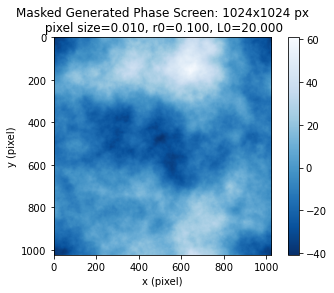

<Figure size 432x288 with 0 Axes>

In [4]:
## 1 Generate 1 infinite screen for structure function##

phase_screen=infinitephasescreen.PhaseScreenVonKarman(scrn_size,pixel_scale,r0,L0)#number of pixel, pixel size, r0, L0
phase=phase_screen.scrn

color_map = plt.cm.get_cmap('Blues')
reversed_color_map = color_map.reversed()

plt.imshow(phase,cmap=reversed_color_map)
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.title('Masked Generated Phase Screen: {:d}x{:d} px\n pixel size={:.3f}, r0={:.3f}, L0={:.3f}'.format(scrn_size,scrn_size,pixel_scale,r0,L0))
plt.colorbar()
plt.show()
plt.clf()

In [5]:
## 2 Make phase structure function ##

## 2.1 randomly choose 10,000 pairs in screen within 3r0 from edge ## 
##     --> int(np.floor(3*r0/pixel_scale)) : scrn_size-int(np.floor(3*r0/pixel_scale)) ##

pointsa=np.zeros((Nrandom,2),dtype=int) # [,0]=x [,1]=y
pointsb=np.zeros((Nrandom,2),dtype=int) # be random shifted vectors limited to certain distance for easy cropping

for i in np.arange(Nrandom):
    pointsa[i,0]=random.randint(int(np.ceil(3*r0/pixel_scale)),scrn_size-int(np.ceil(3*r0/pixel_scale)))
    pointsa[i,1]=random.randint(int(np.ceil(3*r0/pixel_scale)),scrn_size-int(np.ceil(3*r0/pixel_scale)))
    pointsb[i,0]=random.randint(-int(np.floor(3*r0/pixel_scale)),int(np.floor(3*r0/pixel_scale)))
    pointsb[i,1]=random.randint(-int(np.floor(3*r0/pixel_scale)),int(np.floor(3*r0/pixel_scale)))

## 2.2 & 2.3 Measure phase difference and distance ##

distance=np.zeros(Nrandom)
phase_difference=np.zeros(Nrandom)

for i in np.arange(Nrandom):
    phase_difference[i]=np.abs(phase[int(pointsa[i,0]),int(pointsa[i,1])]
                               -phase[int(pointsa[i,0]+pointsb[i,0]),int(pointsa[i,1]+pointsb[i,1])])
    distance[i]=np.sqrt(pointsb[i,0]**2+pointsb[i,1]**2)*pixel_scale


In [6]:
x=set(distance)
x=list(x)
x=np.asarray(x)
x=np.sort(x)

y=[]

for i in x: # for coverd distance
    z=[]
    for j in np.arange(Nrandom):
        if distance[j]==i:
            z.append(phase_difference[j])
    y.append(z)

var_phase=np.zeros(len(y))
for i in np.arange(len(y)):
    temp=0.
    for j in np.arange(len(y[i])):
        temp=temp+(y[i][j]**2)
    temp=temp/len(y[i])
    var_phase[i]=temp

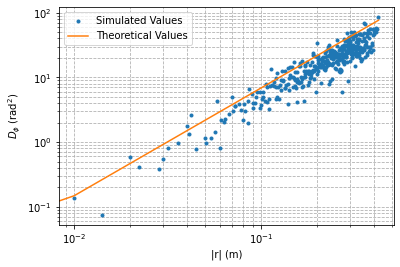

<Figure size 432x288 with 0 Axes>

In [8]:
plt.plot(x,var_phase,ls='',marker='.',label='Simulated Values')
plt.plot(x,6.88*(x/r0)**(5./3.),ls='-',label='Theoretical Values')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('|r| (m)')
plt.ylabel('$D_\phi$ (rad$^2$)')
plt.grid(True,which="both", linestyle='--')
plt.legend()
plt.savefig('StructureFunction')
plt.show()
plt.clf()